Dati filtrati:
[[27.2052 40.5   ]
 [26.676  40.5   ]
 [21.4704 32.7   ]
 [16.2036 21.9   ]
 [16.1532 21.3   ]
 [17.1468 22.    ]
 [17.37   22.6   ]
 [17.55   21.7   ]
 [13.1256 18.1   ]
 [12.4848 17.5   ]
 [15.0624 19.6   ]
 [19.2852 25.7   ]
 [25.3548 34.7   ]
 [23.3136 34.9   ]
 [22.806  34.    ]
 [23.0328 33.1   ]
 [ 7.5456 10.4   ]
 [ 6.8076 10.8   ]
 [ 6.7176  9.9   ]
 [ 7.182   9.8   ]
 [ 7.2504  9.5   ]
 [ 8.1756  9.9   ]
 [11.7    12.9   ]
 [17.4132 21.9   ]
 [17.7264 23.7   ]
 [20.4516 26.1   ]
 [22.1436 26.5   ]
 [22.3236 27.5   ]
 [25.6572 31.5   ]
 [19.0044 23.4   ]
 [13.41   15.7   ]
 [13.3956 16.2   ]
 [ 7.7436 10.9   ]
 [ 7.4304 10.1   ]
 [12.2724 15.9   ]
 [23.7168 32.8   ]
 [24.1092 33.5   ]
 [22.6152 29.5   ]
 [17.3484 20.    ]
 [15.3936 18.3   ]
 [ 7.1532 10.1   ]
 [ 7.7616 10.9   ]
 [10.7172 14.3   ]
 [11.5884 15.3   ]
 [12.0672 15.5   ]
 [12.186  14.9   ]
 [12.3624 16.2   ]
 [19.3248 25.8   ]
 [21.0636 25.3   ]
 [27.1836 34.6   ]
 [11.4552 14.6   ]
 [ 7.2252 11.9  

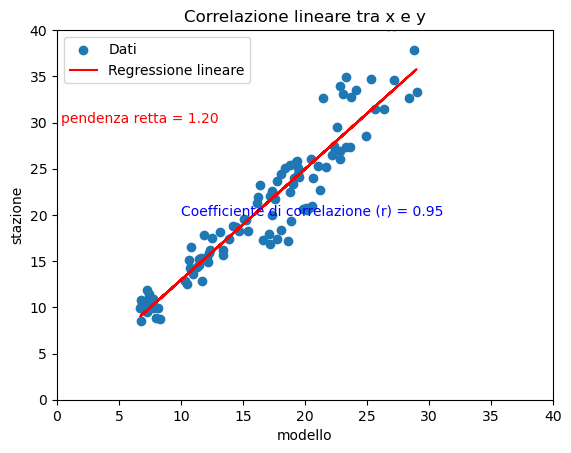

In [1]:
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
# Connessione al database SQLite
conn = sqlite3.connect(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\nuvole.db')
cursor = conn.cursor()

# Query per selezionare i dati dalle colonne desiderate della tabella
query_dati = "SELECT modello, stazione FROM st83clearsky WHERE modello IS NOT NULL AND modello != 'NULL' AND stazione IS NOT NULL AND stazione != 'NULL'"
cursor.execute(query_dati)
filtered_rows = cursor.fetchall()

# Chiusura della connessione al database
conn.close()

# Filtraggio dei dati nelle righe ottenute
filtered_data = [(float(row[0]), float(row[1])) for row in filtered_rows]

# Converti i dati in array NumPy
filtered_data = np.array(filtered_data)

# Estrai x e y dai dati filtrati
x = filtered_data[:, 0]
y = filtered_data[:, 1]

# Stampa dei dati filtrati
print("Dati filtrati:")
print(filtered_data)


# Calcolo della retta di regressione lineare
slope, intercept = np.polyfit(x, y, 1)
line = slope * x + intercept

# Calcolo del coefficiente di correlazione lineare (r)
r = np.corrcoef(x, y)[0, 1]

# Creazione del grafico
plt.scatter(x, y, label='Dati')
plt.plot(x, line, color='red', label='Regressione lineare')

# Aggiunta del coefficiente di correlazione lineare (r) come testo nel grafico
plt.text(10, 20, f'Coefficiente di correlazione (r) = {r:.2f}', fontsize=10, color='blue')
plt.text(0.3, 30, f'pendenza retta = {slope:.2f}', fontsize=10, color='red')

# Aggiunta di titoli e legenda
plt.title('Correlazione lineare tra x e y')
plt.xlabel('modello')
plt.ylabel('stazione')
plt.legend()
plt.xlim(0,40)
plt.ylim(0,40)
# Mostra il grafico
plt.show()